# Express Links · Week 1, step 2: data preparation

This notebook turns the raw METR-LA and PEMS-BAY speed files into the train, validation and test sets that every later run will use.

What it does, in the order of the plan:

1. Downloads the raw speed files (`metr-la.h5`, `pems-bay.h5`) into your Google Drive.
2. Builds inputs and outputs: the past hour (12 readings, 5 minutes apart) plus time of day as input, the next hour (12 readings) as output.
3. Splits 70 / 10 / 20 **by time**: the earliest 70% of samples for training, the next 10% for validation, the last 20% for testing.
4. Masks zero readings: zeros are kept as `0` in the files, and the loss and every metric ignore them (Graph WaveNet's `masked_mae` with `null_val=0`). Nothing is deleted or filled in, so a missing reading can never be mistaken for a jam.
5. Saves `train.npz`, `val.npz`, `test.npz` per dataset in exactly the format Graph WaveNet's `util.load_dataset` reads.
6. Writes down the split dates, the share of masked readings and the shapes, in `data_summary.md` and `data_summary.json`.

**Run it top to bottom** (Runtime → Run all). A CPU runtime is enough; no GPU needed for this step. It takes about 10 minutes, most of it saving PEMS-BAY.

# Week 1 · Step 2: Data preparation (METR-LA and PEMS-BAY)

**Project:** Express Links. Can adding a few well-placed links to the road graph help a traffic GNN (Graph WaveNet) warn about jams 30–60 minutes early?
**This notebook:** turns the raw speed files into the training, validation and test sets that **every later run uses**.

---

## 1. Why this step matters

The project compares **7 versions of the road graph** (original, random links, express links, and so on) using the **same model**.
That comparison is only fair if **the graph is the only thing that changes**. So the data is prepared **once, here**, and every run reads the same files.

Two rules protect that fairness:

* **Split by time, not at random.** The model trains on earlier weeks and is tested on later ones, as in real use. A random split would let it see days next to the test days, and the scores would look better than they really are.
* **Zero readings are missing data, not jams.** A sensor that stops reporting shows **0 mph**, which looks exactly like a sudden, severe jam. Zeros are kept in the files as `0` and **ignored** by the loss and every metric (`masked_mae` with `null_val = 0`).

---

## 2. What the raw data is

Loop detectors in motorway lanes report, every **5 minutes**, the **average speed (mph)** of all cars that passed over them in that 5-minute period.

| | METR-LA | PEMS-BAY |
|---|---|---|
| Where | Motorways, Los Angeles County | Motorways, San Jose area (Bay Area) |
| Sensors | 207 | 325 |
| Period | 1 Mar – 27 Jun 2012 | 1 Jan – 30 Jun 2017 |
| Table size | 34,272 timestamps × 207 sensors | 52,116 timestamps × 325 sensors |

* **One reading** = average speed at one sensor over one 5-minute period. Example: 66.6 means cars averaged 66.6 mph (about 107 km/h).
* Free-flowing traffic is about **60–70 mph**; jams are far lower. **0 = no reading** (sensor offline), never real traffic.
* The data is **speed only**: no traffic volume, incidents or weather, and **motorways only**.

**The road graph** (`adj_mx.pkl`, `adj_mx_bay.pkl`): how strongly each pair of sensors is connected, based on **driving distance along the road**. It's directional (A→B is not the same as B→A). Graph WaveNet uses it to pass information between roads, and step 4 computes effective resistance R on it.

---

## 3. What this notebook produces

Each **sample** is one "past hour → next hour" example, centred on a moment called **"now"** (the anchor):

| Array | Shape | Meaning |
|---|---|---|
| `x` | (samples, 12, sensors, 2) | **Input:** the 12 readings of the **past hour** at every sensor |
| `y` | (samples, 12, sensors, 2) | **Target:** the 12 readings of the **next hour** (train on `y[..., 0]`) |
| `t_anchor` | (samples,) | Date and time of each sample's "now" |
| `t_index` | (samples,) | Row of "now" in the raw table |

* Last axis: `[..., 0]` = **speed (mph)**, `[..., 1]` = **time of day** as a fraction of 24 h (07:05 = 425 ÷ 1440 = 0.2951). The time of day lets the model tell rush hour from 3 am.
* Horizons in `y`: index **2 = 15 min**, **5 = 30 min**, **11 = 60 min** ahead.
* Split **70 / 10 / 20 by time** into `train.npz`, `val.npz`, `test.npz`. Exact dates, sizes and missing shares are in `data/processed/data_summary.md`.
* Built **exactly as Graph WaveNet's official script** builds them, so our baseline can be compared with published results.

**Example from the test set (weekday morning), sensor 767542:**

| Time | 07:05 | 07:10 | 07:15 | 07:20 | 07:25 |
|---|---|---|---|---|---|
| Avg speed (mph) | 57.3 | 35.5 | 26.2 | 22.4 | 20.7 |

A jam forming: a drop of 35+ mph in 20 minutes, while a nearby sensor stays at 66–68 mph. The project's question is whether the model, seeing the hour before, can **warn 30–60 minutes earlier** that this road is about to jam.

---

## 4. How this connects to the other steps

| Step | What it uses from here |
|---|---|
| **3. Baseline** | Trains Graph WaveNet on these files. It should reach about **3.5 mph MAE at 60 min**; if not, fix the setup before any comparison runs. |
| **4–5. Effective resistance R, bottleneck report** | The road-graph files downloaded here; the sensor maps are the starting point for the bottleneck map. |
| **6. Delayed match ρ** | **Training data only.** Stop at the "last reading training may use" date in `data_summary.md`, or the test period leaks in. |
| **8 and 11. Toy city, Sharjah** | Must be saved in **this same format**, so one training and scoring code works on all four datasets. |
| **9. Scoring** | Uses `t_anchor` and the 30/60-min horizons to find real jams and check the forecasts made before them. |
| **Weeks 3–5. 84 main runs + K sweep** | Every run loads these files; **only the graph file changes**. |
| **Report, section 4** | The summary table and figures go straight into Experimental setup. |

---

## 5. Notes for whoever trains the model

* The **data card** cell at the end shows the files, a real worked example, the normalisation numbers and the exact baseline command.
* Graph WaveNet's `train.py` has `--seed` **commented out**. Switch it back on for the 3-seed runs. Use `--device cuda:0` on Colab (its default is `cuda:3`).
* Run the baseline with **learned links switched off** (no `--addaptadj`, no `--randomadj`), so the graph we give is the only thing that changes.

**Folders:** raw files are in `Coding/data/raw/`, training files in `Coding/data/processed/<dataset>/`, figures in `Coding/figures/`.

## 1. Connect Google Drive

Everything is saved under `MyDrive/express-links/` so it survives when Colab disconnects. Change `PROJECT_DIR` if your team uses a shared folder.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os

# Shared team folder: AdvML_F26_Project_&_Survey_Paper / Project / Coding
CANDIDATES = [
    # Use this path if you signed in to Colab with your university account (the folder's owner)
    '/content/drive/MyDrive/AdvML_F26_Project_&_Survey_Paper/Project/Coding',
    # Use this path if you signed in with another account and added a shortcut to the shared folder
    '/content/drive/.shortcut-targets-by-id/1BXg48qqID3HutKK7oqQzm59_HW3HAVcM/AdvML_F26_Project_&_Survey_Paper/Project/Coding',
    '/content/drive/MyDrive/Project/Coding',
]

PROJECT_DIR = next((p for p in CANDIDATES if os.path.isdir(p)), None)
assert PROJECT_DIR, ("Couldn't find the 'Coding' folder. Mount Drive with b00108492@aus.edu, "
                     "or in Drive right-click 'AdvML_F26_Project_&_Survey_Paper' -> Organize -> Add shortcut -> My Drive, then rerun.")
print('PROJECT_DIR =', PROJECT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PROJECT_DIR = /content/drive/MyDrive/AdvML_F26_Project_&_Survey_Paper/Project/Coding


In [2]:
import os, json, time
import numpy as np
import pandas as pd

RAW_DIR  = os.path.join(PROJECT_DIR, 'data', 'raw')          # the .h5 speed files
OUT_ROOT = os.path.join(PROJECT_DIR, 'data', 'processed')    # train/val/test .npz files
os.makedirs(RAW_DIR, exist_ok=True)
os.makedirs(OUT_ROOT, exist_ok=True)

DATASETS = {
    'METR-LA':  'metr-la.h5',
    'PEMS-BAY': 'pems-bay.h5',
}

# Settings from proposal 3.2 (do not change without updating the plan)
SEQ_IN, SEQ_OUT = 12, 12                 # past hour in, next hour out (5-minute readings)
TRAIN_FRAC, TEST_FRAC = 0.7, 0.2         # validation gets the 10% in between
print('Raw files go to:      ', RAW_DIR)
print('Processed files go to:', OUT_ROOT)

Raw files go to:       /content/drive/MyDrive/AdvML_F26_Project_&_Survey_Paper/Project/Coding/data/raw
Processed files go to: /content/drive/MyDrive/AdvML_F26_Project_&_Survey_Paper/Project/Coding/data/processed


## 2. Download the raw speed files

These are the standard files published with DCRNN (Li et al., 2018), the same ones Graph WaveNet uses. The cell skips any file you already have.

**If the download fails** (Google Drive sometimes says "too many users have viewed or downloaded this file"): open the [DCRNN data folder](https://drive.google.com/open?id=10FOTa6HXPqX8Pf5WRoRwcFnW9BrNZEIX) in your browser, download `metr-la.h5` and `pems-bay.h5`, upload both into `MyDrive/express-links/data/raw/`, and rerun this cell.

It also fetches the two road-graph files (`adj_mx.pkl`, `adj_mx_bay.pkl`) from the DCRNN GitHub repo. This step does not use them, but step 3 (the baseline) and step 4 (effective resistance) will.

In [3]:
!pip -q install gdown tables

import subprocess, glob, shutil

missing = [f for f in DATASETS.values() if not os.path.exists(os.path.join(RAW_DIR, f))]
if missing:
    tmp = '/content/dcrnn_download'
    subprocess.run(['gdown', '--folder', '10FOTa6HXPqX8Pf5WRoRwcFnW9BrNZEIX', '-O', tmp, '--quiet'])
    for f in missing:
        hits = glob.glob(os.path.join(tmp, '**', f), recursive=True)
        if hits:
            shutil.copy(hits[0], os.path.join(RAW_DIR, f))

# Road graphs (sensor ids + distance-based adjacency) for later steps
import urllib.request
for f in ['adj_mx.pkl', 'adj_mx_bay.pkl', 'graph_sensor_locations.csv', 'graph_sensor_locations_bay.csv']:
    dst = os.path.join(RAW_DIR, f)
    if not os.path.exists(dst) or os.path.getsize(dst) == 0:
        urllib.request.urlretrieve(f'https://raw.githubusercontent.com/liyaguang/DCRNN/master/data/sensor_graph/{f}', dst)

for f in sorted(os.listdir(RAW_DIR)):
    print(f'{f:35s} {os.path.getsize(os.path.join(RAW_DIR, f))/1e6:8.1f} MB')

still_missing = [f for f in DATASETS.values() if not os.path.exists(os.path.join(RAW_DIR, f))]
assert not still_missing, f'Still missing {still_missing}: download them by hand (see the note above) and rerun this cell.'

adj_mx.pkl                               0.7 MB
adj_mx_bay.pkl                           1.7 MB
graph_sensor_locations.csv               0.0 MB
graph_sensor_locations_bay.csv           0.0 MB
metr-la.h5                              57.0 MB
pems-bay.h5                            135.9 MB


## 3. Look at the raw data

Each file is a table: one row per 5-minute timestamp, one column per sensor, values are speeds in mph. Check that the printout matches the expected values in the right-hand column; if it does not, stop and tell the team.

In [4]:
EXPECTED = {   # from the DCRNN paper / repo
    'METR-LA':  dict(sensors=207, start='2012-03-01', end='2012-06-27', rows=34272),
    'PEMS-BAY': dict(sensors=325, start='2017-01-01', end='2017-06-30', rows=52116),
}

raw = {}
for name, fname in DATASETS.items():
    df = pd.read_hdf(os.path.join(RAW_DIR, fname))
    df = df.sort_index()
    raw[name] = df

    steps = df.index.to_series().diff().dropna()
    n_cells = df.size
    exp = EXPECTED[name]
    print(f'==== {name} ====')
    print(f'  timestamps x sensors : {df.shape}            expected ({exp["rows"]}, {exp["sensors"]})')
    print(f'  first / last reading : {df.index[0]} -> {df.index[-1]}   expected {exp["start"]} -> {exp["end"]}')
    print(f'  time step            : {steps.mode()[0]}  (gaps that are not 5 min: {(steps != pd.Timedelta("5min")).sum()})')
    print(f'  zero readings        : {(df.values == 0).sum():,} of {n_cells:,} = {(df.values == 0).mean():.2%}')
    print(f'  NaN readings         : {np.isnan(df.values).sum():,}')
    print(f'  speed range (non-zero): {df.values[df.values > 0].min():.1f} to {df.values.max():.1f} mph')
    print()

==== METR-LA ====
  timestamps x sensors : (34272, 207)            expected (34272, 207)
  first / last reading : 2012-03-01 00:00:00 -> 2012-06-27 23:55:00   expected 2012-03-01 -> 2012-06-27
  time step            : 0 days 00:05:00  (gaps that are not 5 min: 0)
  zero readings        : 575,302 of 7,094,304 = 8.11%
  NaN readings         : 0
  speed range (non-zero): 0.3 to 70.0 mph

==== PEMS-BAY ====
  timestamps x sensors : (52116, 325)            expected (52116, 325)
  first / last reading : 2017-01-01 00:00:00 -> 2017-06-30 23:55:00   expected 2017-01-01 -> 2017-06-30
  time step            : 0 days 00:05:00  (gaps that are not 5 min: 1)
  zero readings        : 521 of 16,937,700 = 0.00%
  NaN readings         : 0
  speed range (non-zero): 3.0 to 85.1 mph



## 4. The functions that build and split the samples

**Building samples.** A sample is anchored at a time *t* (the last observed reading):

* input `x` = readings at *t − 55 min … t* (12 steps), each with 2 features: speed and time of day (0.0 = midnight, 0.5 = noon);
* output `y` = readings at *t + 5 … t + 60 min* (12 steps), same 2 features. Training uses only the speed; the time-of-day copy is kept so the files match Graph WaveNet's format.

So `x` has shape *(samples, 12, sensors, 2)* and `y` the same. This reproduces Graph WaveNet's `generate_training_data.py` exactly (same anchors, same rounding of the split), so our baseline can be compared with published numbers. The only differences: values are stored as `float32` instead of `float64` (halves memory; the model trains in `float32` anyway), and each file also stores the anchor timestamp of every sample (`t_anchor`) and its row number (`t_index`), which the jam-scoring code will need in week 2.

**Splitting.** Samples are kept in time order and cut into the first 70%, the next 10% and the last 20%. No shuffling before the cut, so the model never trains on a period later than the one it is tested on.

**Masking.** We count how many readings are zero in each part. A zero means the sensor reported nothing; the loss and the metrics skip those readings.

In [5]:
def build_samples(df, seq_in=SEQ_IN, seq_out=SEQ_OUT):
    '''x: (S, seq_in, N, 2), y: (S, seq_out, N, 2); feature 0 = speed, 1 = time of day.'''
    T, N = df.shape
    speed = df.values.astype(np.float32)
    tod = ((df.index.values - df.index.values.astype('datetime64[D]')) / np.timedelta64(1, 'D')).astype(np.float32)
    data = np.stack([speed, np.broadcast_to(tod[:, None], (T, N))], axis=-1)       # (T, N, 2)

    anchors = np.arange(seq_in - 1, T - seq_out)                                    # t = last observed step
    x_off = np.arange(-(seq_in - 1), 1)                                             # -11 .. 0
    y_off = np.arange(1, seq_out + 1)                                               # 1 .. 12
    x = data[anchors[:, None] + x_off[None, :]]
    y = data[anchors[:, None] + y_off[None, :]]
    return x, y, anchors, x_off, y_off


def split_sizes(num_samples, train_frac=TRAIN_FRAC, test_frac=TEST_FRAC):
    '''Same rounding as Graph WaveNet's generate_training_data.py.'''
    num_test = round(num_samples * test_frac)
    num_train = round(num_samples * train_frac)
    num_val = num_samples - num_test - num_train
    return num_train, num_val, num_test


def prepare_dataset(name, df, out_root=OUT_ROOT):
    out_dir = os.path.join(out_root, name)
    os.makedirs(out_dir, exist_ok=True)

    x, y, anchors, x_off, y_off = build_samples(df)
    n_tr, n_va, n_te = split_sizes(len(anchors))
    parts = {'train': slice(0, n_tr), 'val': slice(n_tr, n_tr + n_va), 'test': slice(n_tr + n_va, None)}
    idx = df.index

    summary = {
        'dataset': name,
        'sensors': int(df.shape[1]),
        'timestamps': int(df.shape[0]),
        'raw_period': [str(idx[0]), str(idx[-1])],
        'raw_zero_share': float((df.values == 0).mean()),
        'x_shape_all': list(x.shape), 'y_shape_all': list(y.shape),
        'splits': {},
    }

    for part, sl in parts.items():
        a = anchors[sl]
        xs, ys = x[sl], y[sl]
        t0 = time.time()
        np.savez_compressed(
            os.path.join(out_dir, f'{part}.npz'),
            x=xs, y=ys,
            x_offsets=x_off.reshape(-1, 1), y_offsets=y_off.reshape(-1, 1),
            t_anchor=idx.values[a].astype('datetime64[ns]'),
            t_index=a,
        )
        first_row, last_row = a[0] - (SEQ_IN - 1), a[-1] + SEQ_OUT        # raw rows this part touches
        summary['splits'][part] = {
            'samples': int(len(a)),
            'x_shape': list(xs.shape), 'y_shape': list(ys.shape),
            'first_anchor': str(idx[a[0]]), 'last_anchor': str(idx[a[-1]]),
            'first_input_reading': str(idx[first_row]), 'last_target_reading': str(idx[last_row]),
            'anchor_rows': [int(a[0]), int(a[-1])],
            'masked_share_inputs':  float((xs[..., 0] == 0).mean()),
            'masked_share_targets': float((ys[..., 0] == 0).mean()),
            'masked_share_raw_rows': float((df.values[first_row:last_row + 1] == 0).mean()),
        }
        print(f'  saved {part:5s}  x {tuple(xs.shape)}  y {tuple(ys.shape)}  ({time.time() - t0:.0f} s)')

    # Last raw row used only by training: later steps (deseasonalising, rho) must stay at or before it
    summary['train_last_raw_row'] = int(anchors[n_tr - 1] + SEQ_OUT)
    summary['train_last_raw_time'] = str(idx[summary['train_last_raw_row']])

    with open(os.path.join(out_dir, 'summary.json'), 'w') as f:
        json.dump(summary, f, indent=2)
    del x, y
    return summary

## 5. Build and save both datasets

PEMS-BAY is the large one (about 1.6 GB per array in memory). If Colab runs out of RAM, restart the runtime, rerun cells 1–4, and run this cell with `DATASETS` set to one dataset at a time.

In [6]:
import gc
summaries = {}
for name in DATASETS:
    print(f'==== {name} ====')
    summaries[name] = prepare_dataset(name, raw[name])
    gc.collect()

==== METR-LA ====
  saved train  x (23974, 12, 207, 2)  y (23974, 12, 207, 2)  (23 s)
  saved val    x (3425, 12, 207, 2)  y (3425, 12, 207, 2)  (2 s)
  saved test   x (6850, 12, 207, 2)  y (6850, 12, 207, 2)  (4 s)
==== PEMS-BAY ====
  saved train  x (36465, 12, 325, 2)  y (36465, 12, 325, 2)  (37 s)
  saved val    x (5209, 12, 325, 2)  y (5209, 12, 325, 2)  (7 s)
  saved test   x (10419, 12, 325, 2)  y (10419, 12, 325, 2)  (12 s)


## 6. Check the saved files

These checks reload what was written and confirm that it is right. Every line should say `OK`; if any `assert` fails, do not use the files.

In [7]:
def check_dataset(name, df):
    d = os.path.join(OUT_ROOT, name)
    f = {p: np.load(os.path.join(d, f'{p}.npz')) for p in ['train', 'val', 'test']}
    s = summaries[name]
    N = df.shape[1]

    for p in f:
        assert f[p]['x'].shape[1:] == (SEQ_IN, N, 2) and f[p]['y'].shape[1:] == (SEQ_OUT, N, 2), p
    print('OK  shapes are (samples, 12, sensors, 2)')

    sizes = [len(f[p]['x']) for p in f]
    total = sum(sizes)
    assert total == df.shape[0] - SEQ_IN - SEQ_OUT + 1
    print(f'OK  split sizes {sizes} = {[round(n / total, 3) for n in sizes]} of {total} samples')

    ta = [f[p]['t_anchor'] for p in f]
    assert all(np.all(np.diff(t) > np.timedelta64(0)) for t in ta)
    assert ta[0][-1] < ta[1][0] and ta[1][-1] < ta[2][0]
    print('OK  samples are in time order and train < val < test')

    # The input and output windows really come from the raw table at the stored anchors
    for p in f:
        for k in [0, len(f[p]['x']) // 2, len(f[p]['x']) - 1]:
            t = int(f[p]['t_index'][k])
            assert np.allclose(f[p]['x'][k, :, :, 0], df.values[t - SEQ_IN + 1: t + 1])
            assert np.allclose(f[p]['y'][k, :, :, 0], df.values[t + 1: t + SEQ_OUT + 1])
    print('OK  x is the 12 readings up to the anchor, y is the 12 readings after it')

    tod = f['train']['x'][..., 1]
    assert tod.min() >= 0 and tod.max() < 1
    assert np.allclose(f['train']['x'][:, :, 0, 1], f['train']['x'][:, :, -1, 1])
    print('OK  time of day is in [0, 1) and the same for every sensor')

    assert not any(np.isnan(f[p]['x']).any() or np.isnan(f[p]['y']).any() for p in f)
    print('OK  no NaNs; missing readings are zeros, to be masked')

    # The last training target comes before the first reading any test sample sees
    assert s['train_last_raw_row'] < s['splits']['test']['anchor_rows'][0] - SEQ_IN + 1
    print('OK  no test reading is used as a training target')


for name in DATASETS:
    print(f'==== {name} ====')
    check_dataset(name, raw[name])
    print()

==== METR-LA ====
OK  shapes are (samples, 12, sensors, 2)
OK  split sizes [23974, 3425, 6850] = [0.7, 0.1, 0.2] of 34249 samples
OK  samples are in time order and train < val < test
OK  x is the 12 readings up to the anchor, y is the 12 readings after it
OK  time of day is in [0, 1) and the same for every sensor
OK  no NaNs; missing readings are zeros, to be masked
OK  no test reading is used as a training target

==== PEMS-BAY ====
OK  shapes are (samples, 12, sensors, 2)
OK  split sizes [36465, 5209, 10419] = [0.7, 0.1, 0.2] of 52093 samples
OK  samples are in time order and train < val < test
OK  x is the 12 readings up to the anchor, y is the 12 readings after it
OK  time of day is in [0, 1) and the same for every sensor
OK  no NaNs; missing readings are zeros, to be masked
OK  no test reading is used as a training target



## 7. Write down the split dates, masked shares and shapes

This produces `data/processed/data_summary.md` (for the report's Experimental setup section) and `data_summary.json` (for code). Paste the table into the team's notes.

In [8]:
def fmt(ts):
    return pd.Timestamp(ts).strftime('%Y-%m-%d %H:%M')

lines = ['# Data summary (Week 1, step 2)', '',
         f'Input: past {SEQ_IN} readings (1 hour) + time of day. Output: next {SEQ_OUT} readings (1 hour). '
         f'Split {int(TRAIN_FRAC*100)}/{int(round((1-TRAIN_FRAC-TEST_FRAC)*100))}/{int(TEST_FRAC*100)} by time, '
         'same procedure as Graph WaveNet. Zero readings are kept as 0 and masked in the loss and metrics.', '']

for name, s in summaries.items():
    lines += [f'## {name}', '',
              f'- Sensors: {s["sensors"]}; timestamps: {s["timestamps"]:,} '
              f'({fmt(s["raw_period"][0])} to {fmt(s["raw_period"][1])})',
              f'- Zero (masked) readings in the raw file: {s["raw_zero_share"]:.2%}',
              f'- Last reading training may use (for deseasonalising and rho in week 2): {fmt(s["train_last_raw_time"])}', '',
              '| Split | Samples | First anchor | Last anchor | x shape | y shape | Masked inputs | Masked targets |',
              '|---|---|---|---|---|---|---|---|']
    for p, sp in s['splits'].items():
        lines.append(f'| {p} | {sp["samples"]:,} | {fmt(sp["first_anchor"])} | {fmt(sp["last_anchor"])} | '
                     f'{tuple(sp["x_shape"])} | {tuple(sp["y_shape"])} | '
                     f'{sp["masked_share_inputs"]:.2%} | {sp["masked_share_targets"]:.2%} |')
    lines.append('')

lines += ['"Anchor" is the last observed reading of a sample: its input covers the 55 minutes before it, '
          'its output the 60 minutes after it.']
report = '\n'.join(lines)

with open(os.path.join(OUT_ROOT, 'data_summary.md'), 'w') as f:
    f.write(report)
with open(os.path.join(OUT_ROOT, 'data_summary.json'), 'w') as f:
    json.dump(summaries, f, indent=2)

from IPython.display import Markdown, display
display(Markdown(report))

# Data summary (Week 1, step 2)

Input: past 12 readings (1 hour) + time of day. Output: next 12 readings (1 hour). Split 70/10/20 by time, same procedure as Graph WaveNet. Zero readings are kept as 0 and masked in the loss and metrics.

## METR-LA

- Sensors: 207; timestamps: 34,272 (2012-03-01 00:00 to 2012-06-27 23:55)
- Zero (masked) readings in the raw file: 8.11%
- Last reading training may use (for deseasonalising and rho in week 2): 2012-05-23 07:40

| Split | Samples | First anchor | Last anchor | x shape | y shape | Masked inputs | Masked targets |
|---|---|---|---|---|---|---|---|
| train | 23,974 | 2012-03-01 00:55 | 2012-05-23 06:40 | (23974, 12, 207, 2) | (23974, 12, 207, 2) | 7.13% | 7.13% |
| val | 3,425 | 2012-05-23 06:45 | 2012-06-04 04:05 | (3425, 12, 207, 2) | (3425, 12, 207, 2) | 6.96% | 6.97% |
| test | 6,850 | 2012-06-04 04:10 | 2012-06-27 22:55 | (6850, 12, 207, 2) | (6850, 12, 207, 2) | 12.11% | 12.11% |

## PEMS-BAY

- Sensors: 325; timestamps: 52,116 (2017-01-01 00:00 to 2017-06-30 23:55)
- Zero (masked) readings in the raw file: 0.00%
- Last reading training may use (for deseasonalising and rho in week 2): 2017-05-07 17:35

| Split | Samples | First anchor | Last anchor | x shape | y shape | Masked inputs | Masked targets |
|---|---|---|---|---|---|---|---|
| train | 36,465 | 2017-01-01 00:55 | 2017-05-07 16:35 | (36465, 12, 325, 2) | (36465, 12, 325, 2) | 0.00% | 0.00% |
| val | 5,209 | 2017-05-07 16:40 | 2017-05-25 18:40 | (5209, 12, 325, 2) | (5209, 12, 325, 2) | 0.01% | 0.01% |
| test | 10,419 | 2017-05-25 18:45 | 2017-06-30 22:55 | (10419, 12, 325, 2) | (10419, 12, 325, 2) | 0.01% | 0.01% |

"Anchor" is the last observed reading of a sample: its input covers the 55 minutes before it, its output the 60 minutes after it.

## Done

Your Drive now has:

```
express-links/data/
├── raw/        metr-la.h5, pems-bay.h5, adj_mx.pkl, adj_mx_bay.pkl, sensor locations
└── processed/
    ├── METR-LA/   train.npz  val.npz  test.npz  summary.json
    ├── PEMS-BAY/  train.npz  val.npz  test.npz  summary.json
    ├── data_summary.md
    └── data_summary.json
```

To use these in Graph WaveNet (step 3), point it at the folder: `python train.py --data <PROJECT_DIR>/data/processed/METR-LA --adjdata <PROJECT_DIR>/data/raw/adj_mx.pkl ...`. Its loader reads `x` and `y` and ignores the extra `t_anchor` and `t_index` arrays.

In [9]:
!pip -q install folium

import os, json, pickle, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap

RAW_DIR  = os.path.join(PROJECT_DIR, 'data', 'raw')
OUT_ROOT = os.path.join(PROJECT_DIR, 'data', 'processed')
DATASETS = {'METR-LA': 'metr-la.h5', 'PEMS-BAY': 'pems-bay.h5'}
FIG_DIR  = os.path.join(PROJECT_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

# Reload what earlier sections made, in case Colab was restarted
if 'raw' not in globals():
    raw = {name: pd.read_hdf(os.path.join(RAW_DIR, f)).sort_index() for name, f in DATASETS.items()}
if 'summaries' not in globals():
    with open(os.path.join(OUT_ROOT, 'data_summary.json')) as f:
        summaries = json.load(f)

GRAPH_FILES = {
    'METR-LA':  dict(locations='graph_sensor_locations.csv',     adj='adj_mx.pkl'),
    'PEMS-BAY': dict(locations='graph_sensor_locations_bay.csv', adj='adj_mx_bay.pkl'),
}
for files in GRAPH_FILES.values():          # fetch sensor locations / road graphs if missing
    for f in files.values():
        dst = os.path.join(RAW_DIR, f)
        if not os.path.exists(dst) or os.path.getsize(dst) == 0:
            urllib.request.urlretrieve(f'https://raw.githubusercontent.com/liyaguang/DCRNN/master/data/sensor_graph/{f}', dst)

# One colour per split, used in every figure; one blue ramp for "how much" (missing share)
SPLIT_COLORS = {'train': '#2a78d6', 'val': '#eb6834', 'test': '#1baf7a'}
BLUE_RAMP = ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b']
INK, MUTED, GRID = '#0b0b0b', '#898781', '#e1e0d9'

plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': '#52514e',
    'xtick.color': MUTED, 'ytick.color': MUTED, 'text.color': INK,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
})

def load_locations(name):
    path = os.path.join(RAW_DIR, GRAPH_FILES[name]['locations'])
    if name == 'METR-LA':
        loc = pd.read_csv(path)[['sensor_id', 'latitude', 'longitude']]
    else:  # the Bay Area file has no header row
        loc = pd.read_csv(path, header=None, names=['sensor_id', 'latitude', 'longitude'])
    loc['sensor_id'] = loc['sensor_id'].astype(str)
    return loc.set_index('sensor_id')

def load_adj(name):
    with open(os.path.join(RAW_DIR, GRAPH_FILES[name]['adj']), 'rb') as f:
        sensor_ids, id_to_ind, adj = pickle.load(f, encoding='latin1')
    return [str(s) for s in sensor_ids], adj

def split_periods(name):
    '''(start, end) of each split, in anchor time.'''
    sp = summaries[name]['splits']
    return {p: (pd.Timestamp(sp[p]['first_anchor']), pd.Timestamp(sp[p]['last_anchor'])) for p in sp}

print('Figures will be saved to', FIG_DIR)

Figures will be saved to /content/drive/MyDrive/AdvML_F26_Project_&_Survey_Paper/Project/Coding/figures


In [10]:
# Rebuild each dataset's time index as a clean DatetimeIndex.
# The .h5 files were saved with an old pandas, and newer pandas fails when it
# tries to resample the old index. Timestamps and values stay exactly the same.
for name in raw:
    old_index = raw[name].index
    raw[name].index = pd.DatetimeIndex(np.asarray(old_index.values, dtype='datetime64[ns]'))
    assert (raw[name].index.values == old_index.values).all()
    print(f'{name}: index rebuilt, {raw[name].index[0]} -> {raw[name].index[-1]}, '
          f'{len(raw[name].index):,} timestamps')

METR-LA: index rebuilt, 2012-03-01 00:00:00 -> 2012-06-27 23:55:00, 34,272 timestamps
PEMS-BAY: index rebuilt, 2017-01-01 00:00:00 -> 2017-06-30 23:55:00, 52,116 timestamps


In [11]:
import folium
from IPython.display import display

# ---- Map background: both free, no API key. Keep ONE option uncommented. ----
# Option 1: Esri light grey (clean, closest to the CARTO look)
TILES = 'https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}'
ATTR  = 'Tiles &copy; Esri &mdash; Esri, DeLorme, NAVTEQ'
MAX_ZOOM = 16

# Option 2: OpenStreetMap (more colourful, more street detail)
# TILES = 'OpenStreetMap'
# ATTR  = None
# MAX_ZOOM = 19
# ------------------------------------------------------------------------------

MISSING_BINS = [0, 0.01, 0.05, 0.10, 0.25, 1.0]          # edges of the 5 colour classes
MISSING_LABELS = ['under 1%', '1 to 5%', '5 to 10%', '10 to 25%', '25% or more']

def missing_color(share):
    return BLUE_RAMP[min(np.searchsorted(MISSING_BINS, share, side='right') - 1, len(BLUE_RAMP) - 1)]

def sensor_table(name):
    df = raw[name]
    vals = df.values
    stats = pd.DataFrame({
        'sensor_id': [str(c) for c in df.columns],
        'missing_share': (vals == 0).mean(axis=0),
        'mean_speed': np.nanmean(np.where(vals > 0, vals, np.nan), axis=0),
    }).set_index('sensor_id')
    return stats.join(load_locations(name), how='left')

def legend_html(name, t):
    counts = pd.cut(t['missing_share'], MISSING_BINS, right=False, labels=MISSING_LABELS).value_counts()
    rows = ''.join(
        f'<div style="display:flex;align-items:center;gap:8px;margin:3px 0">'
        f'<span style="width:12px;height:12px;border-radius:50%;background:{c};border:1px solid #c3c2b7"></span>'
        f'<span style="flex:1">{lab}</span><span style="color:#898781">{counts.get(lab, 0)}</span></div>'
        for c, lab in zip(BLUE_RAMP, MISSING_LABELS))
    return (f'<div style="position:fixed;top:12px;right:12px;z-index:9999;background:#fcfcfbee;'
            f'padding:10px 12px;border-radius:8px;border:1px solid #e1e0d9;font:12px sans-serif;'
            f'color:#0b0b0b;min-width:170px">'
            f'<div style="font-weight:600;margin-bottom:2px">{name}: {len(t)} sensors</div>'
            f'<div style="color:#52514e;margin-bottom:6px">Readings missing (sensors)</div>{rows}'
            f'<div style="display:flex;align-items:center;gap:8px;margin-top:6px">'
            f'<span style="width:16px;height:0;border-top:2px solid #a8a69e"></span>'
            f'<span>road-graph link</span></div></div>')

def sensor_map(name):
    t = sensor_table(name)
    placed = t.dropna(subset=['latitude'])
    m = folium.Map(tiles=TILES, attr=ATTR, max_zoom=MAX_ZOOM, control_scale=True)
    m.fit_bounds([placed[['latitude', 'longitude']].min().tolist(),
                  placed[['latitude', 'longitude']].max().tolist()], padding=(20, 20))

    ids, adj = load_adj(name)
    pos = placed[['latitude', 'longitude']]
    links = set()
    for i, j in zip(*np.nonzero(adj)):
        a, b = ids[i], ids[j]
        if i != j and (b, a) not in links and a in pos.index and b in pos.index:
            links.add((a, b))
    for a, b in links:
        folium.PolyLine([pos.loc[a].tolist(), pos.loc[b].tolist()],
                        color='#a8a69e', weight=1, opacity=0.7).add_to(m)

    for sid, r in placed.sort_values('missing_share').iterrows():   # worst sensors drawn on top
        folium.CircleMarker(
            location=[r.latitude, r.longitude], radius=5,
            color='#52514e', weight=0.8, fill=True, fill_opacity=0.95,
            fill_color=missing_color(r.missing_share),
            tooltip=(f'<b>{name} sensor {sid}</b><br>'
                     f'average speed: {r.mean_speed:.1f} mph<br>'
                     f'missing: {r.missing_share:.1%}'),
        ).add_to(m)

    m.get_root().html.add_child(folium.Element(legend_html(name, t)))
    m.save(os.path.join(FIG_DIR, f'sensor_map_{name}.html'))
    print(f'{name}: {len(placed)} of {len(t)} sensors placed, {len(links)} road-graph links')
    return m

maps = {name: sensor_map(name) for name in DATASETS}
display(maps['METR-LA'])

METR-LA: 207 of 207 sensors placed, 1313 road-graph links
PEMS-BAY: 325 of 325 sensors placed, 2079 road-graph links


In [12]:
display(maps['PEMS-BAY'])

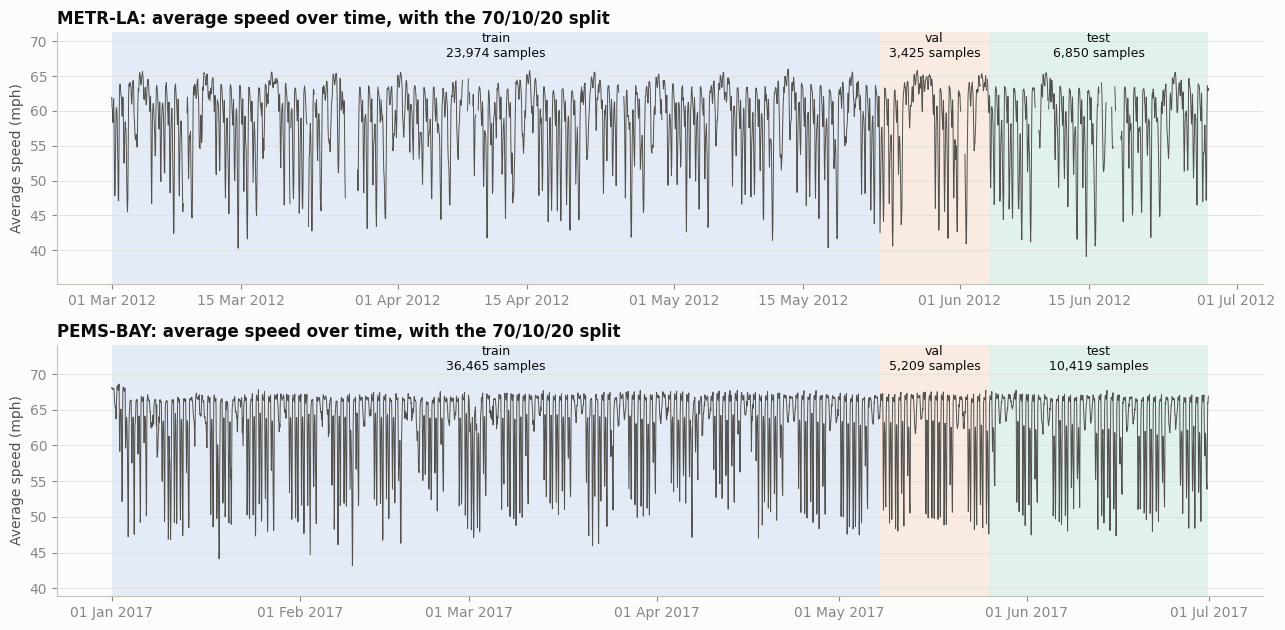

In [13]:
fig, axes = plt.subplots(len(DATASETS), 1, figsize=(13, 3.2 * len(DATASETS)))
axes = np.atleast_1d(axes)

for ax, name in zip(axes, DATASETS):
    df = raw[name]
    hourly = df.where(df > 0).mean(axis=1).resample('1h').mean()
    periods = split_periods(name)
    top = hourly.max() * 1.08
    for p, (start, end) in periods.items():
        ax.axvspan(start, end, color=SPLIT_COLORS[p], alpha=0.12, lw=0)
        n = summaries[name]['splits'][p]['samples']
        ax.text(start + (end - start) / 2, top, f'{p}\n{n:,} samples',
                ha='center', va='top', fontsize=9, color=INK)
    ax.plot(hourly.index, hourly.values, color='#52514e', lw=0.7)
    ax.set_ylim(hourly.min() * 0.9, top)
    ax.set_ylabel('Average speed (mph)')
    ax.set_title(f'{name}: average speed over time, with the 70/10/20 split', loc='left')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b %Y'))
    ax.grid(axis='x', visible=False)

fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'split_timeline.png'), dpi=200, bbox_inches='tight')
plt.show()

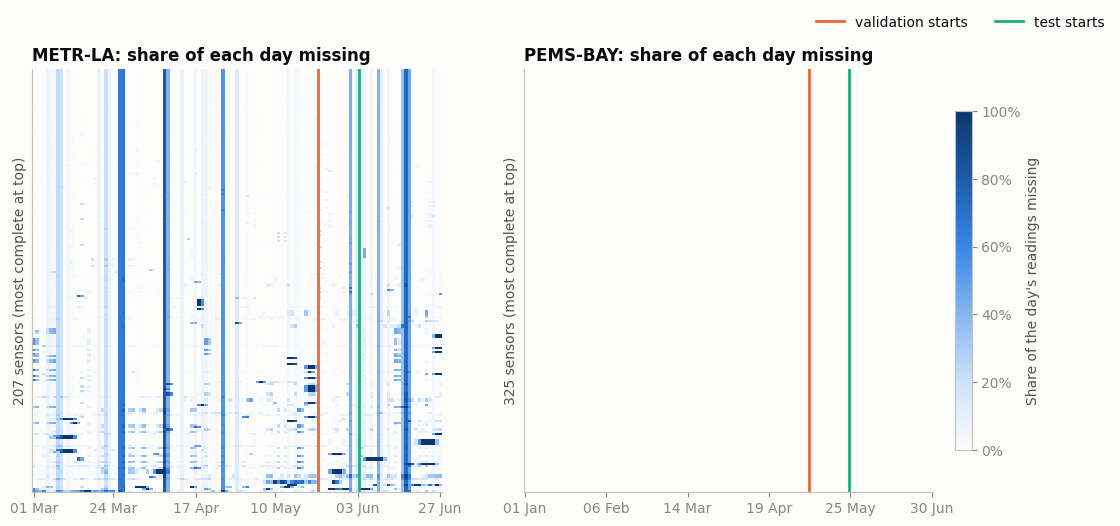

In [14]:
missing_cmap = LinearSegmentedColormap.from_list('missing', ['#fcfcfb'] + BLUE_RAMP)

fig, axes = plt.subplots(1, len(DATASETS), figsize=(14, 5.5))
axes = np.atleast_1d(axes)

for ax, name in zip(axes, DATASETS):
    df = raw[name]
    daily = (df == 0).resample('1D').mean()               # days x sensors
    order = daily.mean(axis=0).sort_values().index        # most complete sensors at the top
    grid = daily[order].T.values
    im = ax.imshow(grid, aspect='auto', cmap=missing_cmap, vmin=0, vmax=1, interpolation='nearest')
    days = daily.index
    for p in ['val', 'test']:
        start = split_periods(name)[p][0].normalize()
        x = days.get_indexer([start], method='nearest')[0]
        ax.axvline(x - 0.5, color=SPLIT_COLORS[p], lw=2,
                   label={'val': 'validation starts', 'test': 'test starts'}[p])
    ticks = np.linspace(0, len(days) - 1, 6).astype(int)
    ax.set_xticks(ticks, [days[i].strftime('%d %b') for i in ticks])
    ax.set_yticks([])
    ax.set_ylabel(f'{df.shape[1]} sensors (most complete at top)')
    ax.set_title(f'{name}: share of each day missing', loc='left')
    ax.grid(False)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right', ncol=2, frameon=False, bbox_to_anchor=(0.9, 1.0))
cbar = fig.colorbar(im, ax=axes, shrink=0.8, pad=0.02)
cbar.set_label('Share of the day\'s readings missing')
cbar.ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
fig.savefig(os.path.join(FIG_DIR, 'missing_heatmap.png'), dpi=200, bbox_inches='tight')
plt.show()

/tmp/ipykernel_22908/3386017419.py:16: RuntimeWarning: All-NaN slice encountered
  s = int(np.nanargmax(np.nanmax(drop, axis=0) - np.nanmin(drop, axis=0)))


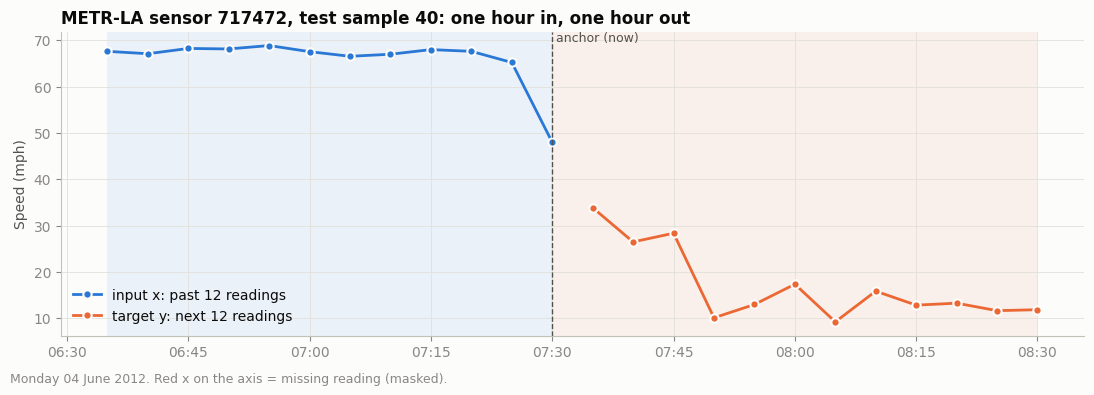

x shape for this sample: (12, 207, 2)   y shape: (12, 207, 2)


In [15]:
NAME = 'METR-LA'
SENSOR = None            # None = the sensor with the biggest speed drop in this hour
ANCHOR_TIME = None       # e.g. '2012-06-05 07:30'; None = first weekday 07:30 in the test set

test = np.load(os.path.join(OUT_ROOT, NAME, 'test.npz'))
t_anchor = pd.to_datetime(test['t_anchor'])
if ANCHOR_TIME is None:
    k = next(i for i, t in enumerate(t_anchor) if t.weekday() < 5 and t.hour == 7 and t.minute == 30)
else:
    k = int(np.argmin(np.abs(t_anchor - pd.Timestamp(ANCHOR_TIME))))

x_speed, y_speed = test['x'][k, :, :, 0], test['y'][k, :, :, 0]
if SENSOR is None:
    both = np.concatenate([x_speed, y_speed])
    drop = np.where(both > 0, both, np.nan)
    s = int(np.nanargmax(np.nanmax(drop, axis=0) - np.nanmin(drop, axis=0)))
else:
    s = [str(c) for c in raw[NAME].columns].index(str(SENSOR))
sensor_id = raw[NAME].columns[s]

anchor = t_anchor[k]
tx = anchor + pd.to_timedelta(test['x_offsets'].ravel() * 5, unit='min')
ty = anchor + pd.to_timedelta(test['y_offsets'].ravel() * 5, unit='min')

def masked(v):
    return np.where(v > 0, v, np.nan)

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.axvspan(tx[0], anchor, color=SPLIT_COLORS['train'], alpha=0.08, lw=0)
ax.axvspan(anchor, ty[-1], color=SPLIT_COLORS['val'], alpha=0.08, lw=0)
ax.plot(tx, masked(x_speed[:, s]), '-o', color=SPLIT_COLORS['train'], lw=2, ms=6,
        mec='#fcfcfb', mew=1.5, label='input x: past 12 readings')
ax.plot(ty, masked(y_speed[:, s]), '-o', color=SPLIT_COLORS['val'], lw=2, ms=6,
        mec='#fcfcfb', mew=1.5, label='target y: next 12 readings')
ax.axvline(anchor, color='#52514e', lw=1, ls='--')
ax.text(anchor, ax.get_ylim()[1], ' anchor (now)', va='top', fontsize=9, color='#52514e')
for t_, v_ in zip(np.concatenate([tx, ty]), np.concatenate([x_speed[:, s], y_speed[:, s]])):
    if v_ == 0:
        ax.plot(t_, ax.get_ylim()[0], marker='x', color='#d03b3b', ms=7)
ax.set_ylabel('Speed (mph)')
ax.set_title(f'{NAME} sensor {sensor_id}, test sample {k:,}: one hour in, one hour out', loc='left')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax.legend(loc='lower left', frameon=False)
fig.text(0.01, -0.02, f'{anchor:%A %d %B %Y}. Red x on the axis = missing reading (masked).',
         fontsize=9, color=MUTED)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'one_sample.png'), dpi=200, bbox_inches='tight')
plt.show()
print('x shape for this sample:', test['x'][k].shape, '  y shape:', test['y'][k].shape)

In [17]:
# ===== Data card: what the training files contain (for whoever trains the model) =====
import os, json, zipfile
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

OUT_ROOT = os.path.join(PROJECT_DIR, 'data', 'processed')
RAW_DIR  = os.path.join(PROJECT_DIR, 'data', 'raw')
SHOW = 'METR-LA'          # dataset used for the worked example below ('METR-LA' or 'PEMS-BAY')
N_SENSORS_SHOWN = 6       # how many sensors to show in the example tables

with open(os.path.join(OUT_ROOT, 'data_summary.json')) as f:
    summ = json.load(f)

def npz_info(path):
    """Shape and dtype of every array in an .npz, read from the file headers (does not load the data)."""
    out = {}
    with zipfile.ZipFile(path) as z:
        for name in z.namelist():
            with z.open(name) as fh:
                version = np.lib.format.read_magic(fh)
                read_header = (np.lib.format.read_array_header_1_0 if version == (1, 0)
                               else np.lib.format.read_array_header_2_0)
                shape, _, dtype = read_header(fh)
            out[name[:-4]] = (shape, dtype)
    return out

# ---------- 1. Files and shapes ----------
rows = []
for name in summ:
    for part in ['train', 'val', 'test']:
        path = os.path.join(OUT_ROOT, name, f'{part}.npz')
        info = npz_info(path)
        sp = summ[name]['splits'][part]
        rows.append({
            'dataset': name, 'split': part,
            'x shape': str(info['x'][0]), 'y shape': str(info['y'][0]), 'dtype': str(info['x'][1]),
            'first "now"': sp['first_anchor'][:16], 'last "now"': sp['last_anchor'][:16],
            'missing targets': f"{sp['masked_share_targets']:.2%}",
            'size on disk': f'{os.path.getsize(path) / 1e6:,.0f} MB',
        })

display(Markdown(f"""
## Data card

**Folder:** `{OUT_ROOT}`  ·  one sub-folder per dataset, each with `train.npz`, `val.npz`, `test.npz`.

Each `.npz` holds:

| Array | Shape | Meaning |
|---|---|---|
| `x` | (samples, 12, sensors, 2) | **Input.** The 12 readings of the past hour (5 min apart) at every sensor. |
| `y` | (samples, 12, sensors, 2) | **Target.** The 12 readings of the next hour. Train on `y[..., 0]` only. |
| `x_offsets` | (12, 1) | Steps of `x` relative to "now": -11 … 0 (× 5 min). |
| `y_offsets` | (12, 1) | Steps of `y` relative to "now": 1 … 12 (× 5 min). |
| `t_anchor` | (samples,) | Date and time of each sample's "now" (its last input reading). |
| `t_index` | (samples,) | Row of "now" in the raw `.h5` table. |

**The last axis (features):** `[..., 0]` = speed in mph (5-minute average over the sensor; **0 = missing, not a jam**),
`[..., 1]` = time of day as a fraction of 24 h (0.0 = midnight, 0.5 = noon).

**Horizons in `y`:** index 2 = 15 min ahead, index 5 = 30 min ahead, index 11 = 60 min ahead.

**Split:** by time, 70 / 10 / 20; train is always earlier than validation, validation earlier than test. Never shuffle across splits.
"""))
display(pd.DataFrame(rows).set_index(['dataset', 'split']))

# ---------- 2. A worked example ----------
test = np.load(os.path.join(OUT_ROOT, SHOW, 'test.npz'))
t_anchor = pd.DatetimeIndex(test['t_anchor'].astype('datetime64[ns]'))
k = next(i for i, t in enumerate(t_anchor) if t.weekday() < 5 and t.hour == 8 and t.minute == 0)   # a weekday 08:00
x, y = test['x'][k], test['y'][k]
now = t_anchor[k]

raw_cols = pd.read_hdf(os.path.join(RAW_DIR, {'METR-LA': 'metr-la.h5', 'PEMS-BAY': 'pems-bay.h5'}[SHOW]), stop=1).columns
sensor_names = [f'sensor {c}' for c in raw_cols[:N_SENSORS_SHOWN]]

def as_table(arr, offsets, label):
    times = [now + pd.Timedelta(minutes=5 * int(o)) for o in offsets.ravel()]
    df = pd.DataFrame(arr[:, :N_SENSORS_SHOWN, 0].astype(float).round(1), columns=sensor_names,
                      index=pd.Index([f'{t:%H:%M} ({int(o) * 5:+d} min)' for t, o in zip(times, offsets.ravel())], name=label))
    df.insert(0, 'time of day (feature 1)', arr[:, 0, 1].astype(float).round(4))
    return df

display(Markdown(f"""
### Worked example: {SHOW} test sample {k:,}, "now" = {now:%A %d %B %Y, %H:%M}

This one sample is a pair of tables. Rows are time steps, columns are sensors (only the first {N_SENSORS_SHOWN} of {x.shape[1]} shown).
Values are speeds in mph; a **0.0** would be a missing reading. The model gets the first table and must predict the speed columns of the second.
"""))
display(as_table(x, test['x_offsets'], 'INPUT x  (what the model sees)'))
display(as_table(y, test['y_offsets'], 'TARGET y  (what it must predict)'))

# ---------- 3. Numbers the trainer needs ----------
import pickle
ADJ_FILE = 'adj_mx.pkl' if SHOW == 'METR-LA' else 'adj_mx_bay.pkl'
with open(os.path.join(RAW_DIR, ADJ_FILE), 'rb') as f:
    graph_ids = [str(s) for s in pickle.load(f, encoding='latin1')[0]]
all_cols = [str(c) for c in pd.read_hdf(os.path.join(RAW_DIR, {'METR-LA': 'metr-la.h5', 'PEMS-BAY': 'pems-bay.h5'}[SHOW]), stop=1).columns]
ORDER_MSG = ('**matches** the sensor axis of `x` and `y` (checked).' if graph_ids == all_cols else
             '**does NOT match** the sensor axis of `x` and `y`. Reorder before training!')

train_x = np.load(os.path.join(OUT_ROOT, SHOW, 'train.npz'))['x'][..., 0]
nonzero = train_x[train_x > 0]
display(Markdown(f"""
### Training notes for {SHOW}

* **Normalisation.** Graph WaveNet's `util.load_dataset` standardises `x[..., 0]` with the mean and std of the training inputs **including zeros**:
  mean = {train_x.mean():.2f} mph, std = {train_x.std():.2f} mph. (Without zeros: mean = {nonzero.mean():.2f}, std = {nonzero.std():.2f}.) Targets `y` stay in mph.
* **Masking.** Train and score with `masked_mae(pred, real, 0.0)` (Graph WaveNet's default), so zero targets are ignored.
  Share of targets that are zero: train {summ[SHOW]['splits']['train']['masked_share_targets']:.2%}, test {summ[SHOW]['splits']['test']['masked_share_targets']:.2%}.
* **Graph.** Road graph: `{os.path.join(RAW_DIR, ADJ_FILE)}`. Sensor order in the graph {ORDER_MSG}
* **Baseline run (step 3)**, from the Graph WaveNet repo, with learned links switched off (no `--addaptadj`, no `--randomadj`):

~~~
python train.py --data {os.path.join(OUT_ROOT, SHOW)} \\
                --adjdata {os.path.join(RAW_DIR, ADJ_FILE)} \\
                --adjtype doubletransition --gcn_bool --num_nodes {x.shape[1]} --seq_length 12 --in_dim 2 \\
                --device cuda:0 --epochs 100
~~~
* **Seeds.** The original `train.py` has its `--seed` option commented out (lines 28 and 39-40). The plan needs fixed seeds,
  so uncomment those lines in our copy of the repo before the comparison runs, then add `--seed 0` (1, 2 for the other runs).
* **Expected baseline** (published Graph WaveNet, METR-LA): MAE about 3.5 mph at 60 min. If ours is far off, fix the setup before any comparison runs.
"""))
del train_x, nonzero


## Data card

**Folder:** `/content/drive/MyDrive/AdvML_F26_Project_&_Survey_Paper/Project/Coding/data/processed`  ·  one sub-folder per dataset, each with `train.npz`, `val.npz`, `test.npz`.

Each `.npz` holds:

| Array | Shape | Meaning |
|---|---|---|
| `x` | (samples, 12, sensors, 2) | **Input.** The 12 readings of the past hour (5 min apart) at every sensor. |
| `y` | (samples, 12, sensors, 2) | **Target.** The 12 readings of the next hour. Train on `y[..., 0]` only. |
| `x_offsets` | (12, 1) | Steps of `x` relative to "now": -11 … 0 (× 5 min). |
| `y_offsets` | (12, 1) | Steps of `y` relative to "now": 1 … 12 (× 5 min). |
| `t_anchor` | (samples,) | Date and time of each sample's "now" (its last input reading). |
| `t_index` | (samples,) | Row of "now" in the raw `.h5` table. |

**The last axis (features):** `[..., 0]` = speed in mph (5-minute average over the sensor; **0 = missing, not a jam**),
`[..., 1]` = time of day as a fraction of 24 h (0.0 = midnight, 0.5 = noon).

**Horizons in `y`:** index 2 = 15 min ahead, index 5 = 30 min ahead, index 11 = 60 min ahead.

**Split:** by time, 70 / 10 / 20; train is always earlier than validation, validation earlier than test. Never shuffle across splits.


x shape              y shape    dtype  \
dataset  split                                                      
METR-LA  train  (23974, 12, 207, 2)  (23974, 12, 207, 2)  float32   
         val     (3425, 12, 207, 2)   (3425, 12, 207, 2)  float32   
         test    (6850, 12, 207, 2)   (6850, 12, 207, 2)  float32   
PEMS-BAY train  (36465, 12, 325, 2)  (36465, 12, 325, 2)  float32   
         val     (5209, 12, 325, 2)   (5209, 12, 325, 2)  float32   
         test   (10419, 12, 325, 2)  (10419, 12, 325, 2)  float32   

                     first "now"        last "now" missing targets  \
dataset  split                                                       
METR-LA  train  2012-03-01 00:55  2012-05-23 06:40           7.13%   
         val    2012-05-23 06:45  2012-06-04 04:05           6.97%   
         test   2012-06-04 04:10  2012-06-27 22:55          12.11%   
PEMS-BAY train  2017-01-01 00:55  2017-05-07 16:35           0.00%   
         val    2017-05-07 16:40  2017-05-25 18:40           0.01%   
         test   2017-05-25 18:45  2017-06-30 22:55           0.01%   

               size on disk  
dataset  split               
METR-LA  train        33 MB  
         val           5 MB  
         test          9 MB  
PEMS-BAY train        78 MB  
         val          11 MB  
         test         22 MB


### Worked example: METR-LA test sample 46, "now" = Monday 04 June 2012, 08:00

This one sample is a pair of tables. Rows are time steps, columns are sensors (only the first 6 of 207 shown).
Values are speeds in mph; a **0.0** would be a missing reading. The model gets the first table and must predict the speed columns of the second.


,time of day (feature 1),sensor 773869,sensor 767541,sensor 767542,sensor 717447,sensor 717446,sensor 717445
INPUT x (what the model sees),,,,,,,
07:05 (-55 min),0.2951,66.6,66.6,57.3,52.7,36.8,56.3
07:10 (-50 min),0.2986,68.8,64.5,35.5,52.0,39.1,50.0
07:15 (-45 min),0.3021,67.6,64.6,26.2,52.1,38.6,52.9
07:20 (-40 min),0.3056,67.9,66.6,22.4,51.0,38.5,55.6
07:25 (-35 min),0.3090,68.1,63.9,20.7,51.4,41.3,53.6
07:30 (-30 min),0.3125,67.5,64.4,23.0,51.4,31.2,55.9
07:35 (-25 min),0.3160,67.7,65.0,28.2,52.2,44.0,54.6
07:40 (-20 min),0.3194,67.0,65.1,21.4,50.0,45.5,54.1
07:45 (-15 min),0.3229,68.1,64.6,22.9,51.8,34.1,51.5


,time of day (feature 1),sensor 773869,sensor 767541,sensor 767542,sensor 717447,sensor 717446,sensor 717445
TARGET y (what it must predict),,,,,,,
08:05 (+5 min),0.3368,67.4,64.6,21.8,51.2,31.2,51.2
08:10 (+10 min),0.3403,67.2,66.4,22.0,50.5,30.0,53.4
08:15 (+15 min),0.3438,66.9,64.3,30.7,53.4,30.1,58.6
08:20 (+20 min),0.3472,67.5,64.6,19.6,45.6,29.2,55.4
08:25 (+25 min),0.3507,67.3,65.8,26.4,51.9,42.2,55.6
08:30 (+30 min),0.3542,66.8,62.4,24.9,51.8,34.9,54.4
08:35 (+35 min),0.3576,67.8,64.8,27.9,52.0,35.3,51.4
08:40 (+40 min),0.3611,67.2,65.1,33.0,48.8,39.2,54.1
08:45 (+45 min),0.3646,68.0,63.3,45.0,49.8,42.9,51.4



### Training notes for METR-LA

* **Normalisation.** Graph WaveNet's `util.load_dataset` standardises `x[..., 0]` with the mean and std of the training inputs **including zeros**:
  mean = 54.41 mph, std = 19.49 mph. (Without zeros: mean = 58.58, std = 12.82.) Targets `y` stay in mph.
* **Masking.** Train and score with `masked_mae(pred, real, 0.0)` (Graph WaveNet's default), so zero targets are ignored.
  Share of targets that are zero: train 7.13%, test 12.11%.
* **Graph.** Road graph: `/content/drive/MyDrive/AdvML_F26_Project_&_Survey_Paper/Project/Coding/data/raw/adj_mx.pkl`. Sensor order in the graph **matches** the sensor axis of `x` and `y` (checked).
* **Baseline run (step 3)**, from the Graph WaveNet repo, with learned links switched off (no `--addaptadj`, no `--randomadj`):

~~~
python train.py --data /content/drive/MyDrive/AdvML_F26_Project_&_Survey_Paper/Project/Coding/data/processed/METR-LA \
                --adjdata /content/drive/MyDrive/AdvML_F26_Project_&_Survey_Paper/Project/Coding/data/raw/adj_mx.pkl \
                --adjtype doubletransition --gcn_bool --num_nodes 207 --seq_length 12 --in_dim 2 \
                --device cuda:0 --epochs 100
~~~
* **Seeds.** The original `train.py` has its `--seed` option commented out (lines 28 and 39-40). The plan needs fixed seeds,
  so uncomment those lines in our copy of the repo before the comparison runs, then add `--seed 0` (1, 2 for the other runs).
* **Expected baseline** (published Graph WaveNet, METR-LA): MAE about 3.5 mph at 60 min. If ours is far off, fix the setup before any comparison runs.
